## Setup

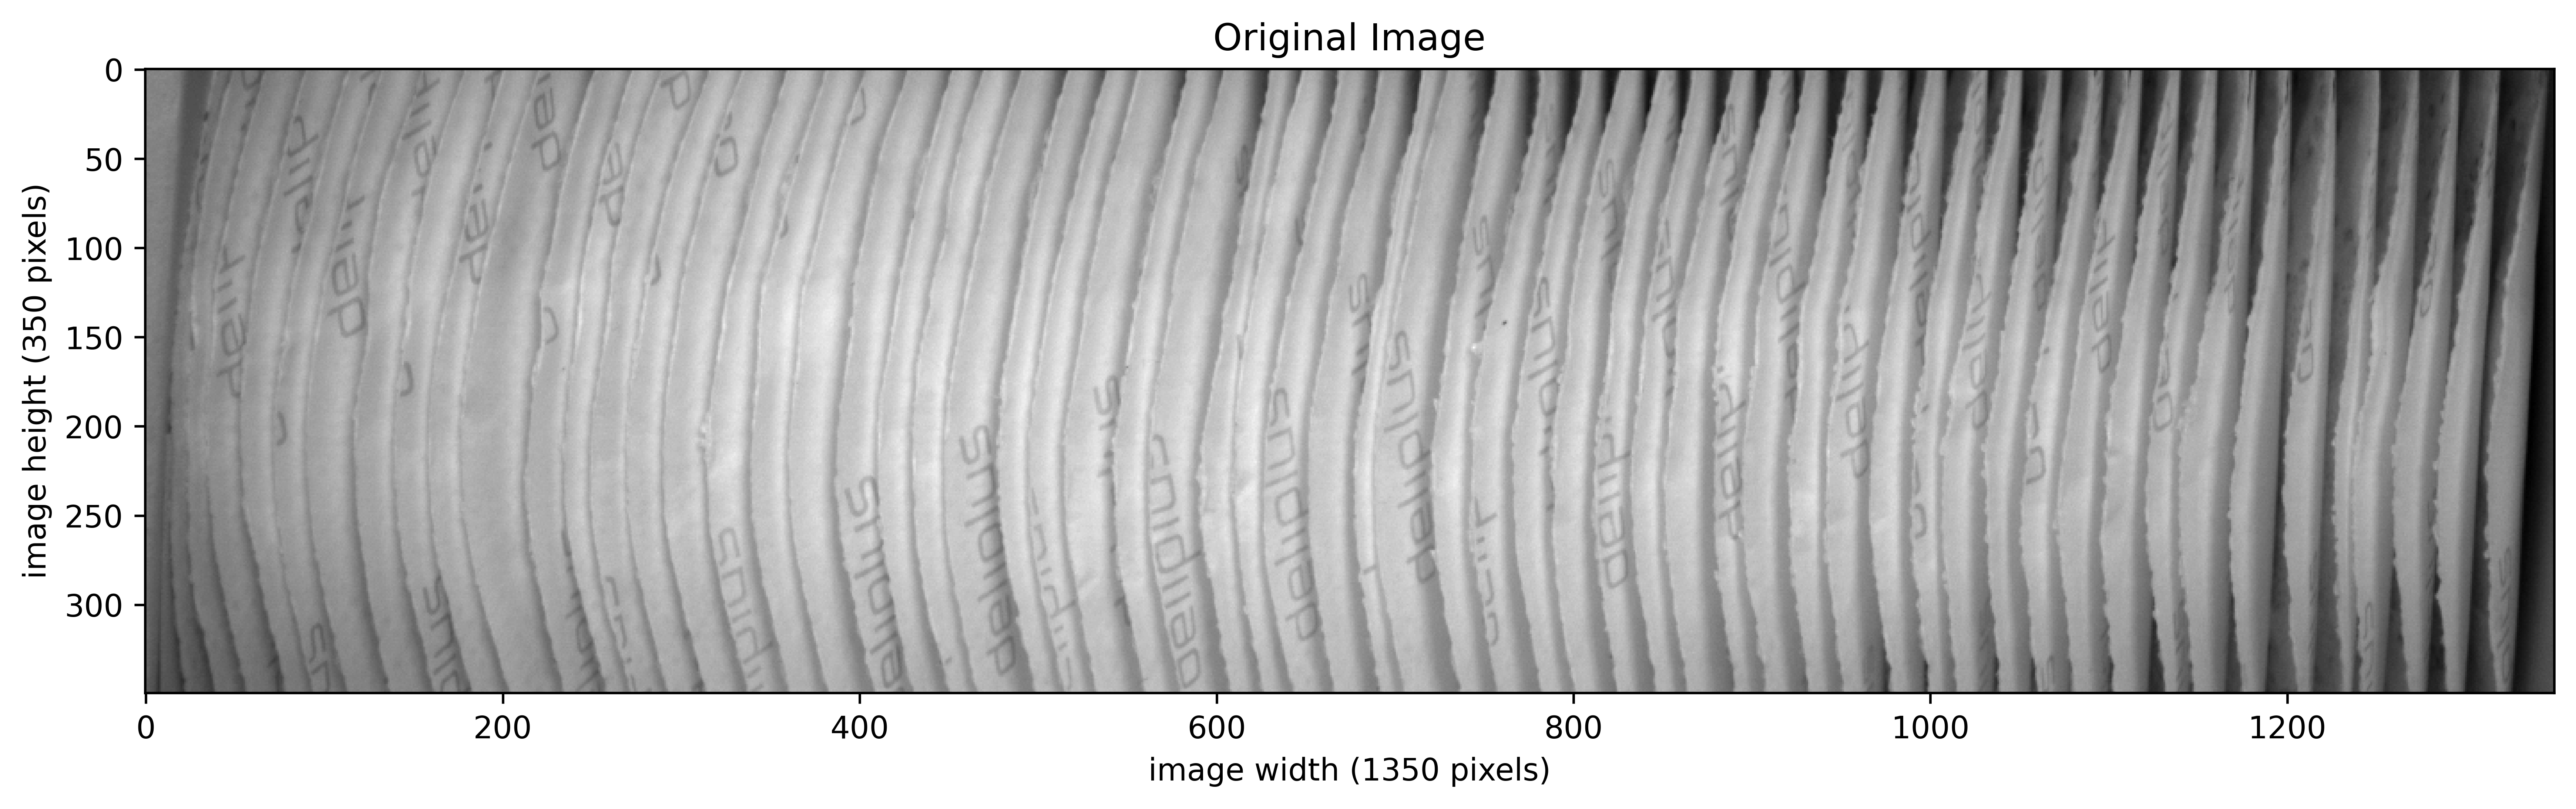

In [94]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('Aufnahmen/image_22_cropped.tiff', cv2.IMREAD_GRAYSCALE)
img = img[100:450, 0:1350]

plt.figure(figsize=(14, 6), dpi=600)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.ylabel('image height (350 pixels)')
plt.xlabel('image width (1350 pixels)')
plt.savefig('presentation/00_original_image.png', dpi=600)

### GaussianBlur

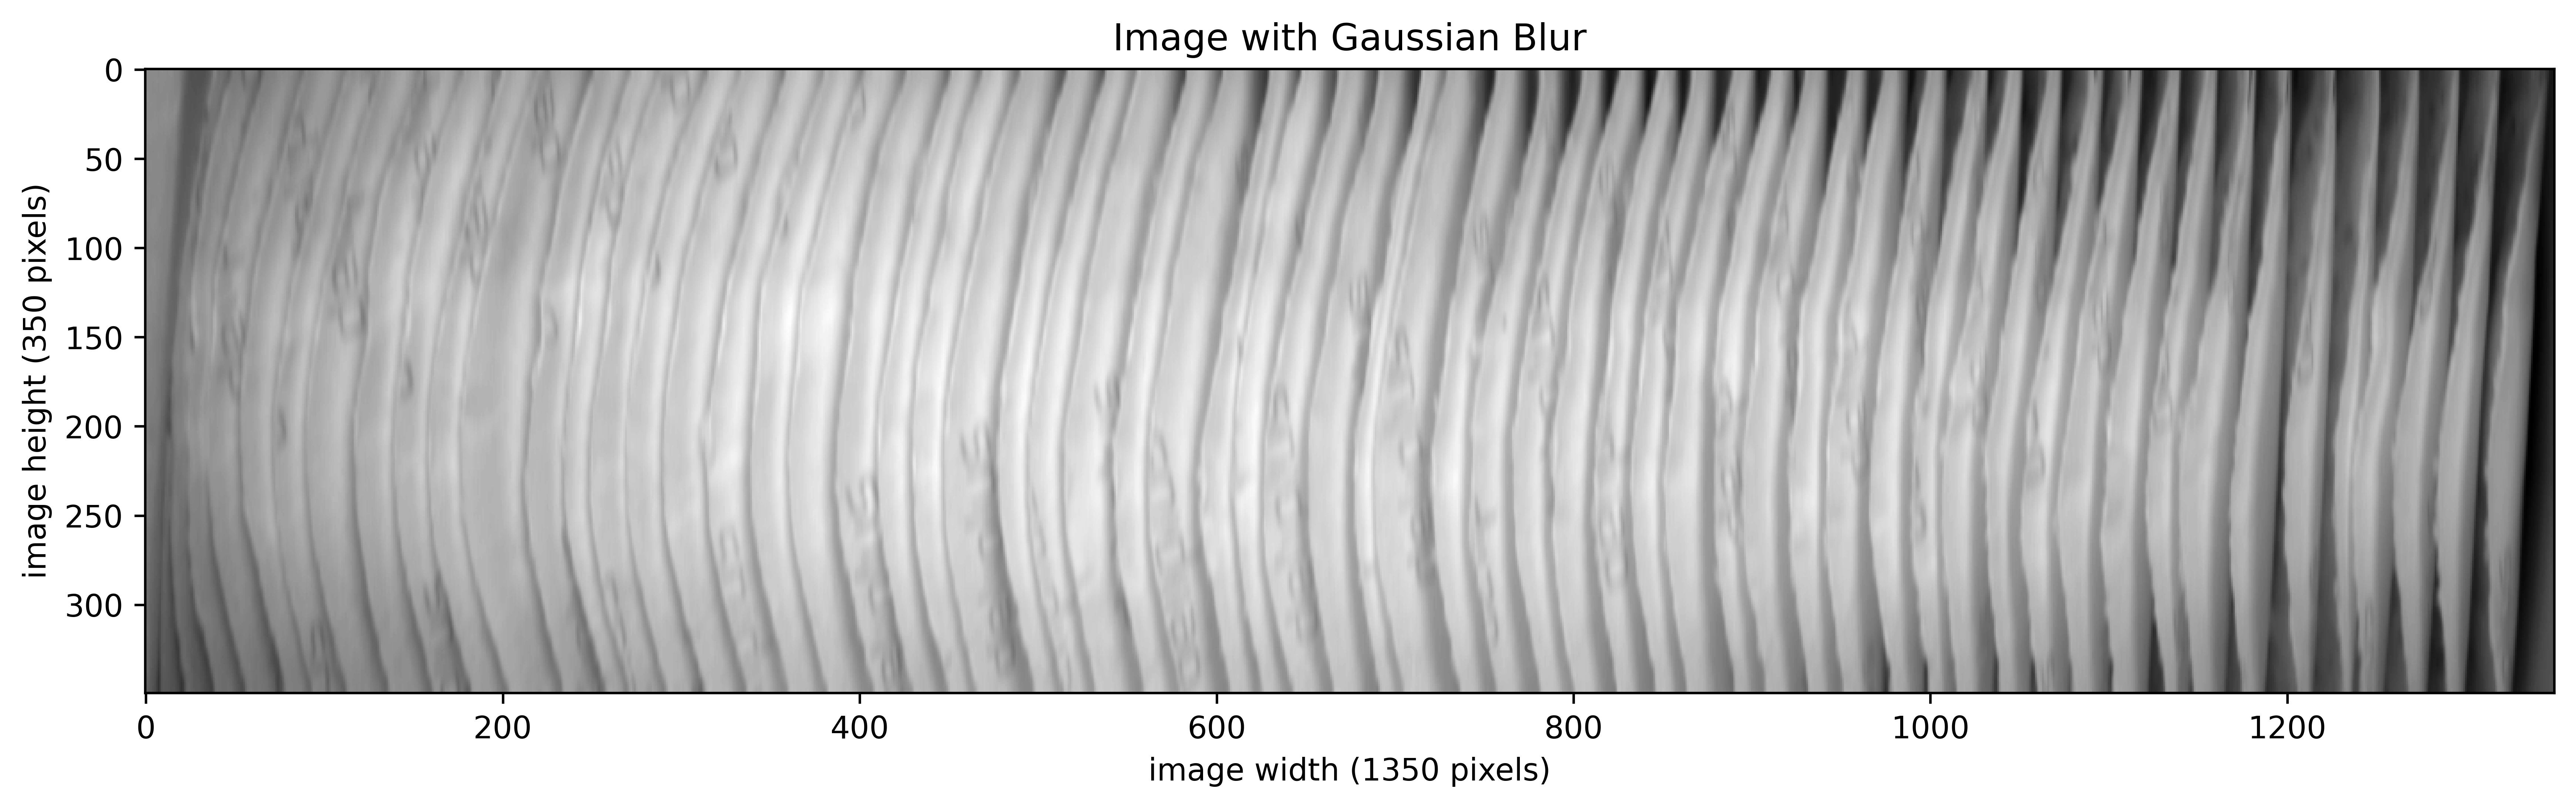

In [95]:
# Apply Gaussian blur only in the horizontal direction (kernel size (5, 1))
img_blur = cv2.GaussianBlur(img, (1, 13), 4)

plt.figure(figsize=(14, 6), dpi=600)
plt.imshow(img_blur, cmap='gray')
plt.title('Image with Gaussian Blur')
plt.ylabel('image height (350 pixels)')
plt.xlabel('image width (1350 pixels)')
plt.savefig('presentation/01_gaussian_blur_image.png', dpi=600)

### Adaptive Threshold

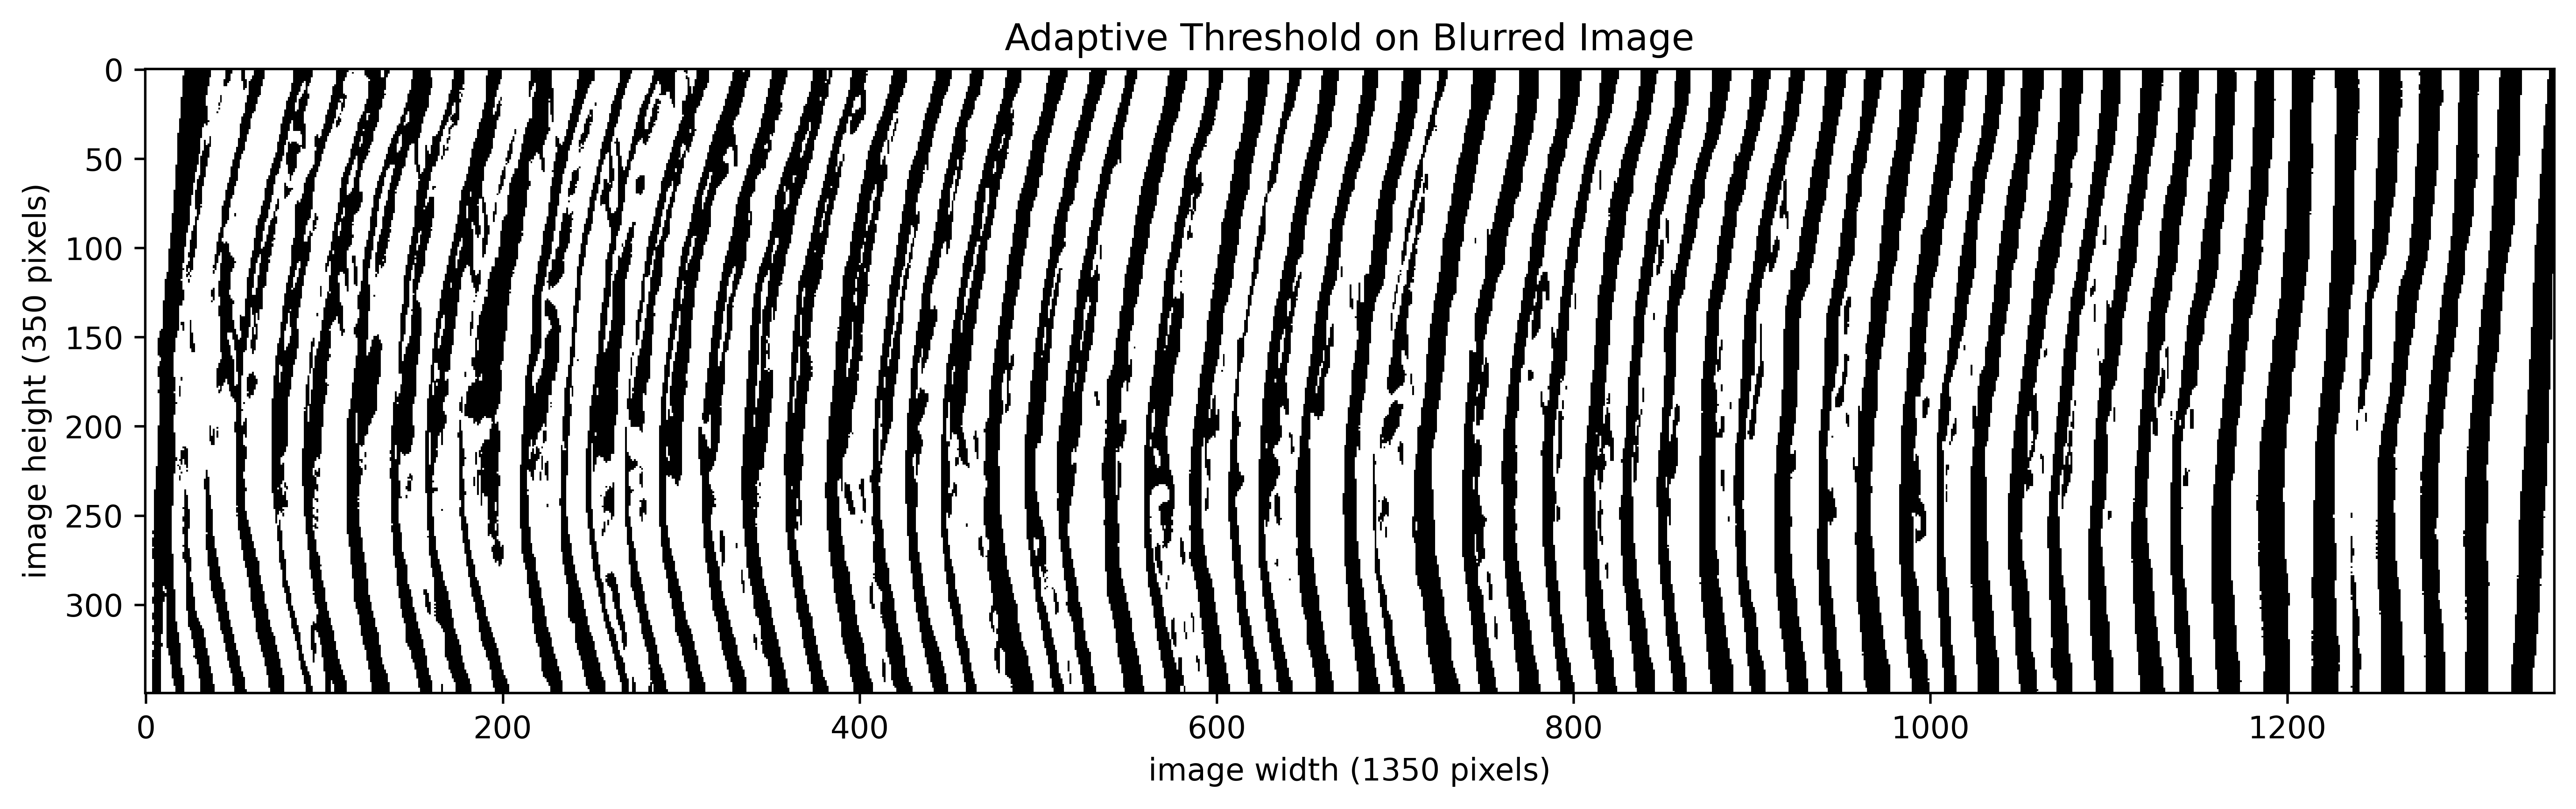

In [96]:
img_blur_edges = cv2.adaptiveThreshold(
    img_blur, 255, 
    cv2.ADAPTIVE_THRESH_MEAN_C, 
    cv2.THRESH_BINARY, 
    31, 2
)

plt.figure(figsize=(14, 6), dpi=600)
plt.imshow(img_blur_edges, cmap='gray')
plt.title('Adaptive Threshold on Blurred Image')
plt.ylabel('image height (350 pixels)')
plt.xlabel('image width (1350 pixels)')

# save figure as image
plt.savefig('presentation/02_adaptive_threshold_blurred_image.png', dpi=600)

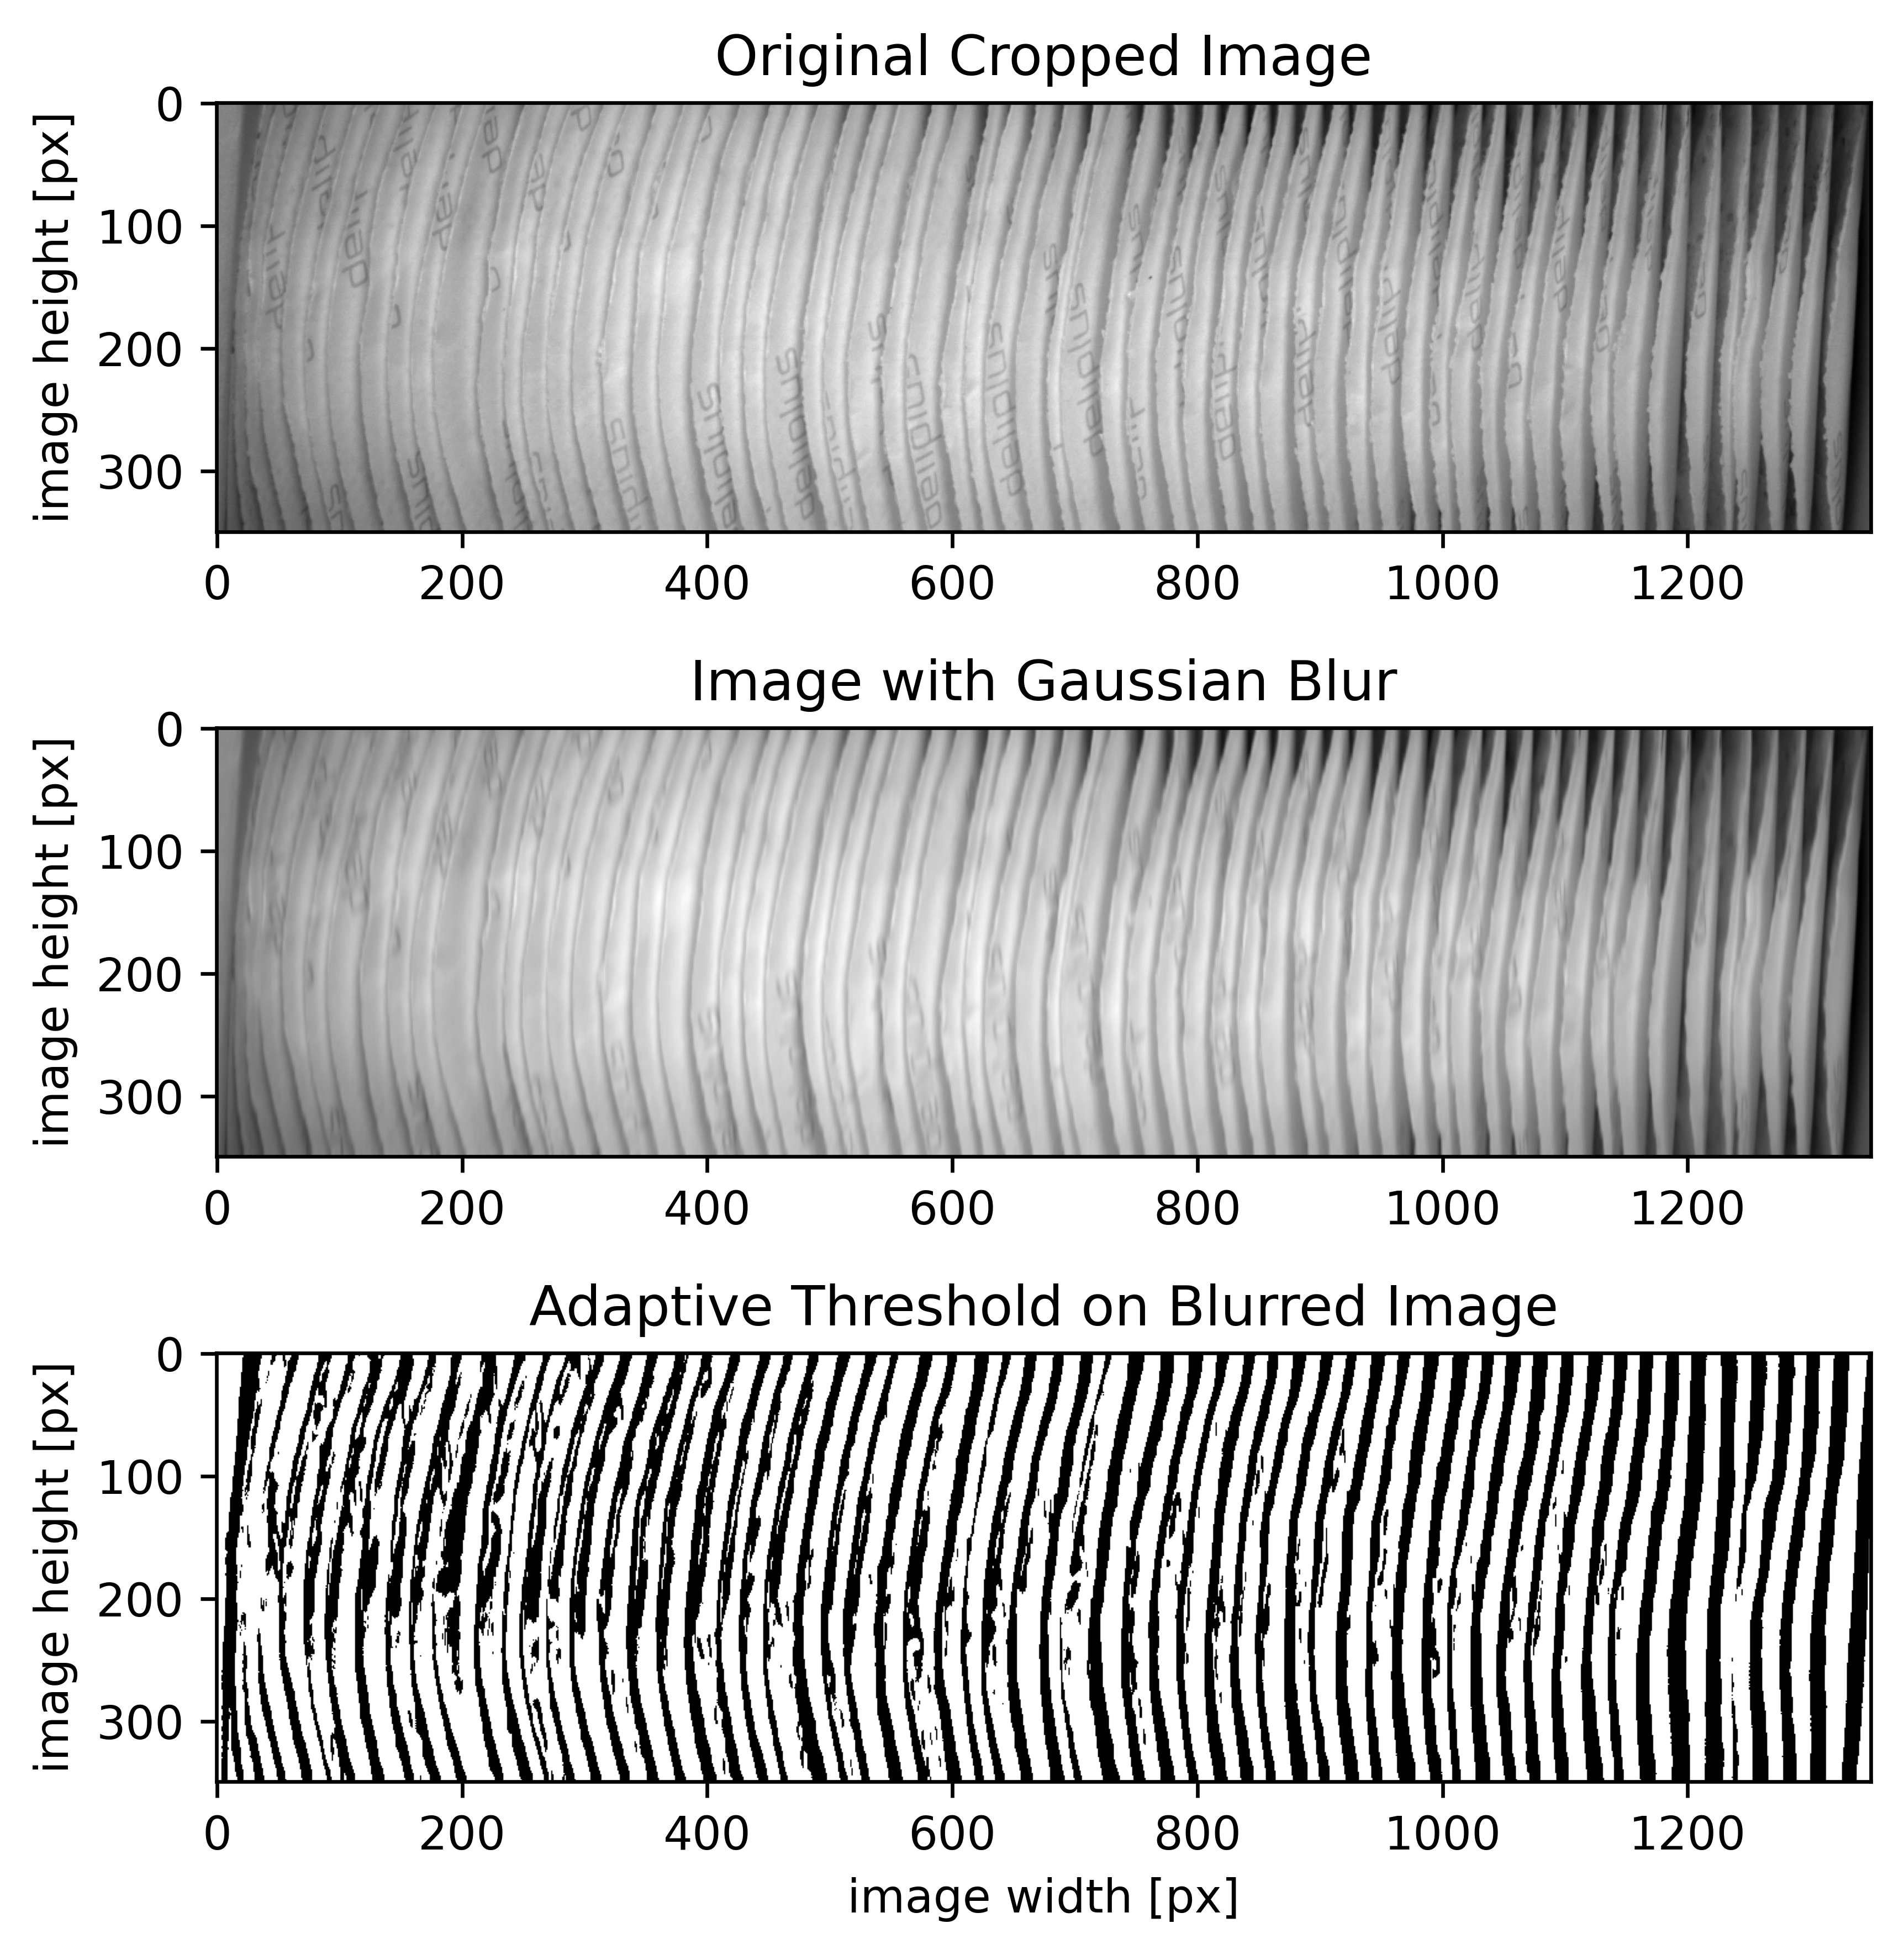

In [97]:
# Figure with 3 Subplots and only one x axis label for original image, gaussian blur and adaptive threshold

plt.figure(figsize=(14, 6), dpi=600)
plt.subplot(3, 1, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Cropped Image')
plt.ylabel('image height [px]')
plt.subplot(3, 1, 2)
plt.imshow(img_blur, cmap='gray')
plt.title('Image with Gaussian Blur')
plt.ylabel('image height [px]')
plt.subplot(3, 1, 3)
plt.imshow(img_blur_edges, cmap='gray')
plt.title('Adaptive Threshold on Blurred Image')
plt.ylabel('image height [px]')
plt.xlabel('image width [px]')
plt.tight_layout()
plt.savefig('presentation/03_combined_plot_original_blur_threshold.png', dpi=600)

### Full image projection

In [ ]:
projection = np.sum(img_blur_edges, axis=0)

plt.figure(figsize=(14, 4))
plt.plot(projection)
plt.title('Projection Full Image')
plt.xlabel('X position')
plt.ylabel('Sum of edge pixels')
plt.show()

## Example ROIs (Top & Bottom)

In [ ]:
roi_1 = img_blur_edges[0:50, :]
roi_2 = img_blur_edges[300:350, :]

In [ ]:
roi_1_projection = np.sum(roi_1, axis=0)/roi_1.shape[0]/255
roi_2_projection = np.sum(roi_2, axis=0)/roi_2.shape[0]/255

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(roi_1_projection)
plt.title('Projection ROI 1 (Top 50 rows)')
plt.xlabel('X position')
plt.ylabel('Sum of edge pixels /50 [rows] /255 [value]')
plt.show()

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(roi_2_projection)
plt.title('Projection ROI 2 (Rows 300-350)')
plt.xlabel('X position')
plt.ylabel('Sum of edge pixels /50 [rows] /255 [value]')
plt.show()

## Dynamic ROIs (5x70)

In [ ]:
# dynamic list or rois (always 70 rows high)
rois = [img_blur_edges[i:i+70, :] for i in range(0, img_blur_edges.shape[0], 70)]

projections = [np.sum(roi, axis=0)/roi.shape[0]/255 for roi in rois]

# export all projections as csv
np.savetxt("processing_data/projections/projections_5x70.csv", np.array(projections), delimiter=",")

In [ ]:
# Load peak data from CSV files

peaks_list = []
for i in range(len(projections)):
    peaks = np.loadtxt(f"processing_data/peaks/5x70/peaks_roi_{i+1}.csv", delimiter=",")
    peaks_list.append(peaks)

In [ ]:
# Calculate the mean and std number of peaks over all ROIs
mean_peaks = np.mean([len(peaks) for peaks in peaks_list])
std_peaks = np.std([len(peaks) for peaks in peaks_list])
print(f"Mean number of peaks: {mean_peaks}")
print(f"Standard deviation of peaks: {std_peaks}")

## Dynamic ROIs (7x50)

In [ ]:
# dynamic list or rois (always 50 rows high)
rois = [img_blur_edges[i:i+50, :] for i in range(0, img_blur_edges.shape[0], 50)]

# compute projections for each roi
projections = [np.sum(roi, axis=0)/roi.shape[0]/255 for roi in rois]

# export all projections as csv
np.savetxt("processing_data/projections/projections.csv", projections, delimiter=",")

In [ ]:
# plot all projections
'''
plt.figure(figsize=(14, 20))
for i, proj in enumerate(projections):
    plt.subplot(len(projections), 1, i+1)
    plt.plot(proj)
    plt.title(f'Projection ROI {i+1} (Rows {i*50}-{i*50+50})')
    plt.xlabel('X position')
    plt.ylabel('Sum of edge pixels /50 [rows] /255 [value]')
plt.tight_layout()
plt.show()
'''

In [ ]:
# Load peak data from CSV files

peaks_list = []
for i in range(len(projections)):
    peaks = np.loadtxt(f"processing_data/peaks/7x50/peaks_roi_{i+1}.csv", delimiter=",")
    peaks_list.append(peaks)

In [ ]:
# Visualize the peaks on the projections
'''
plt.figure(figsize=(14, 20))
for i, (proj, peaks) in enumerate(zip(projections, peaks_list)):
    plt.subplot(len(projections), 1, i+1)
    plt.plot(proj)
    if peaks.size > 0:
        plt.plot(peaks.astype(int), proj[peaks.astype(int)], "x")
    plt.title(f'Projection ROI {i+1} with {len(peaks)} Peaks')
    plt.xlabel('X position')
    plt.ylabel('Sum of edge pixels /50 [rows] /255 [value]')
plt.tight_layout()
plt.show()
'''

In [ ]:
# Calculate the mean and std number of peaks over all ROIs
mean_peaks = np.mean([len(peaks) for peaks in peaks_list])
std_peaks = np.std([len(peaks) for peaks in peaks_list])
print(f"Mean number of peaks: {mean_peaks}")
print(f"Standard deviation of peaks: {std_peaks}")

# Calculate the median and IQR number of peaks over all ROIs
median_peaks = np.median([len(peaks) for peaks in peaks_list])
q1 = np.percentile([len(peaks) for peaks in peaks_list], 25)
q3 = np.percentile([len(peaks) for peaks in peaks_list], 75)

print(f"Median number of peaks: {median_peaks}")
print(f"Interquartile range (IQR) of peaks: {q1} - {q3}")


## Dynamic ROIs (10x35)

In [98]:
# dynamic list or rois (always 35 rows high)
rois = [img_blur_edges[i:i+35, :] for i in range(0, img_blur_edges.shape[0], 35)]

# compute projections for each roi
projections = [np.sum(roi, axis=0)/roi.shape[0]/255 for roi in rois]

# export all projections as csv
np.savetxt("processing_data/projections/projections_10x35.csv", projections, delimiter=",")

In [99]:
# Load peak data from CSV files

peaks_list = []
for i in range(len(projections)):
    peaks = np.loadtxt(f"processing_data/peaks/10x35/peaks_roi_{i+1}.csv", delimiter=",")
    peaks_list.append(peaks)

In [100]:
# Calculate the mean and std number of peaks over all ROIs
mean_peaks = np.mean([len(peaks) for peaks in peaks_list])
std_peaks = np.std([len(peaks) for peaks in peaks_list])
print(f"Mean number of peaks: {mean_peaks}")
print(f"Standard deviation of peaks: {std_peaks}")

# Calculate the median and IQR number of peaks over all ROIs
median_peaks = np.median([len(peaks) for peaks in peaks_list])
q1 = np.percentile([len(peaks) for peaks in peaks_list], 25)
q3 = np.percentile([len(peaks) for peaks in peaks_list], 75)

print(f"Median number of peaks: {median_peaks}")
print(f"Interquartile range (IQR) of peaks: {q1} - {q3}")

Mean number of peaks: 60.0
Standard deviation of peaks: 1.0
Median number of peaks: 60.0
Interquartile range (IQR) of peaks: 59.0 - 60.75


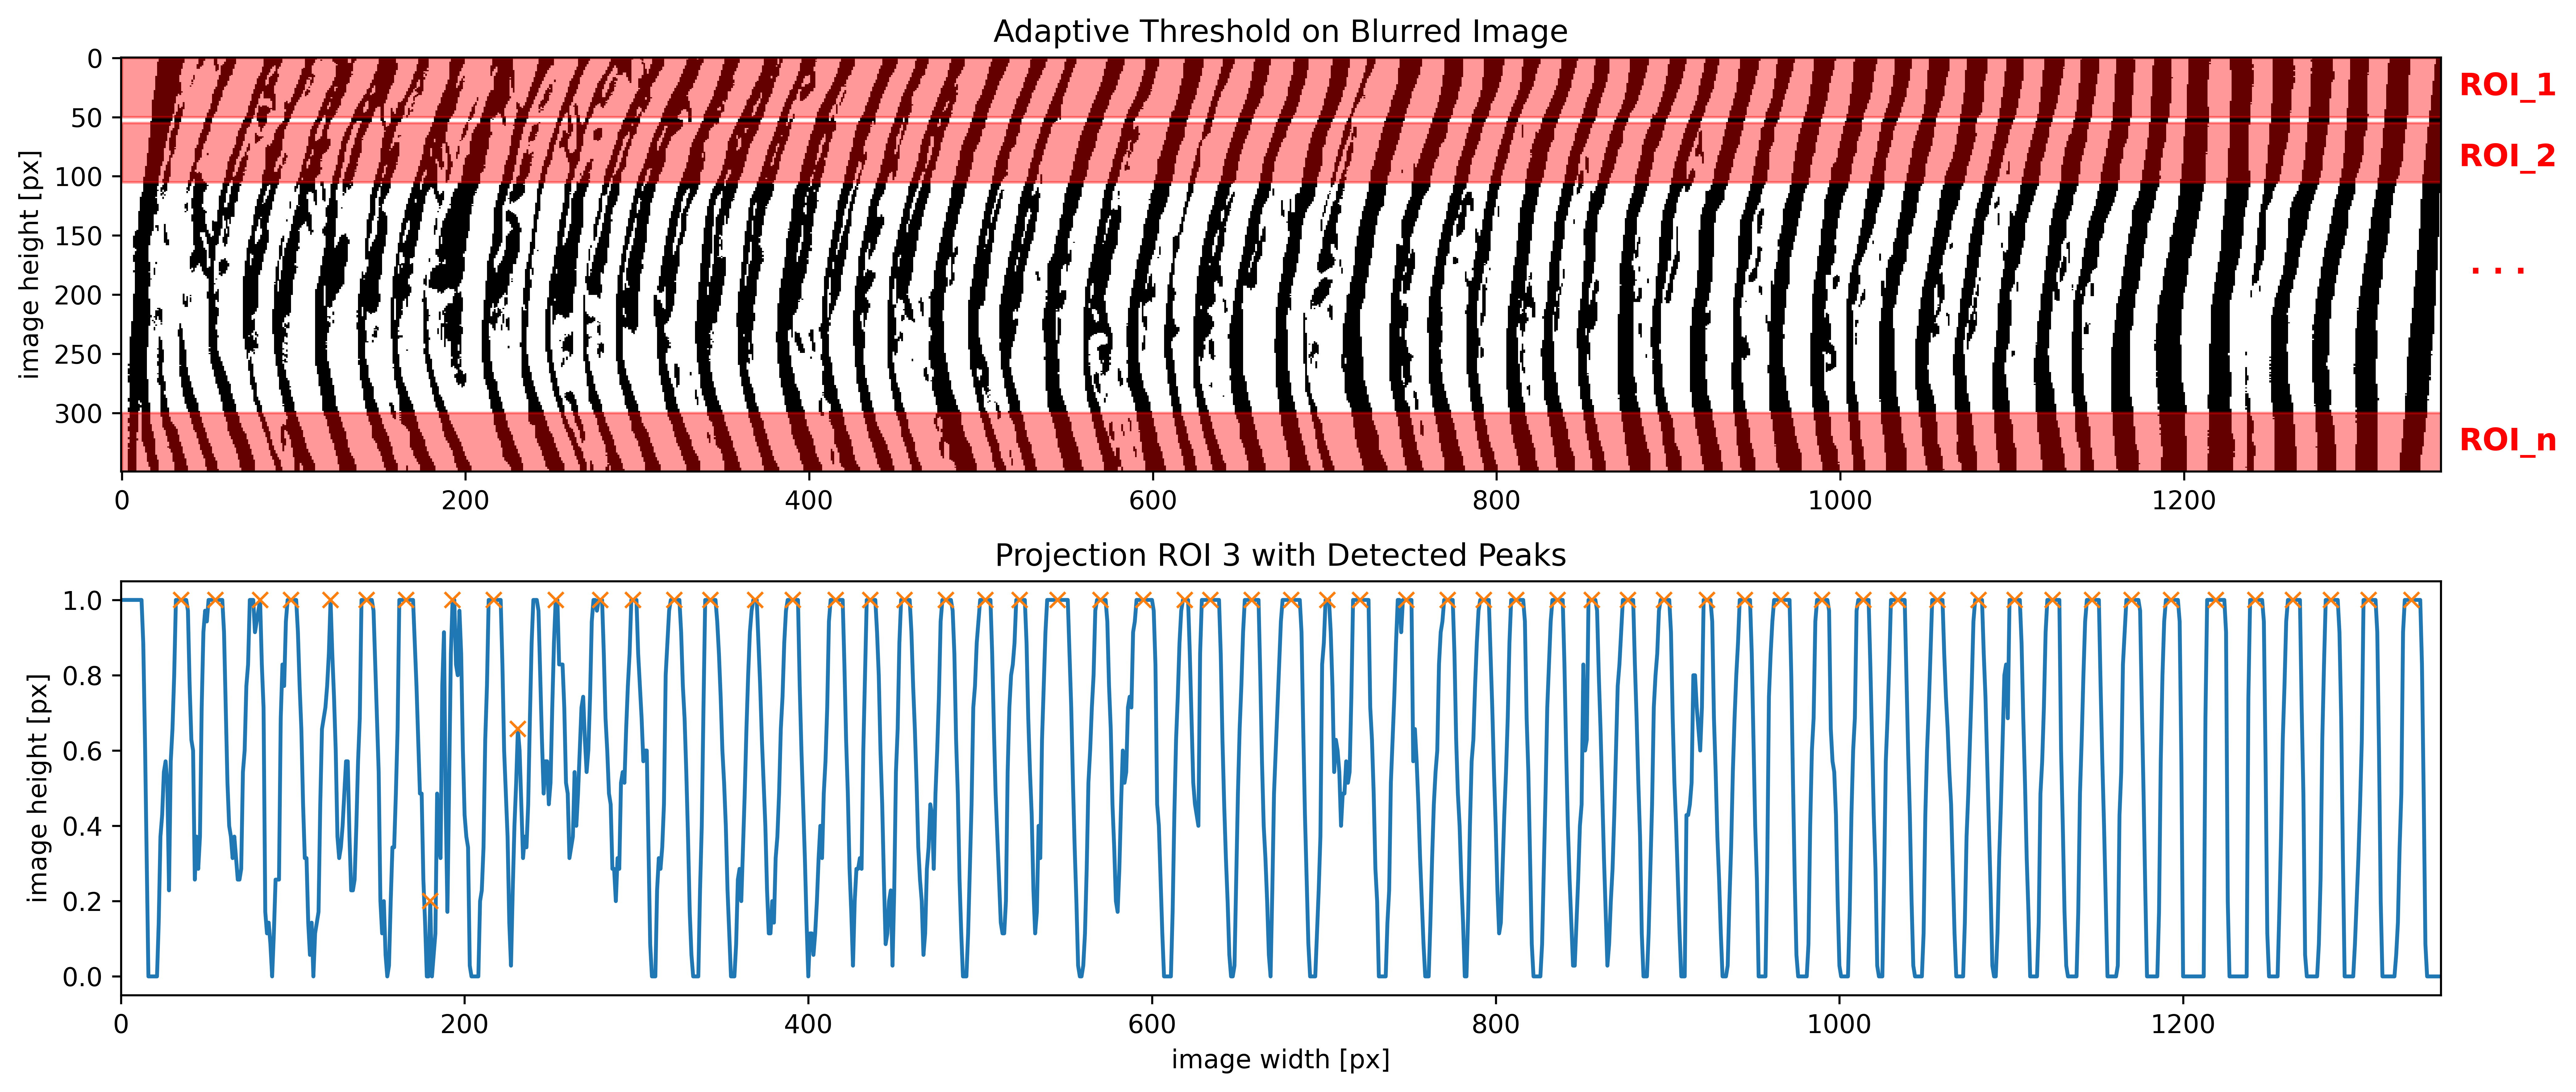

In [113]:
import matplotlib.patches as patches

plt.figure(figsize=(14, 6), dpi=600)

plt.subplot(2, 1, 1)
plt.imshow(img_blur_edges, cmap='gray', aspect='auto')

# Rectangle at the top (ROI_1)
rect_top = patches.Rectangle(
    (0, 0), img_blur_edges.shape[1], 50, 
    linewidth=1, edgecolor='r', facecolor='red', alpha=0.4
)
plt.gca().add_patch(rect_top)
plt.text(
    img_blur_edges.shape[1] + 10, 25, "ROI_1", 
    va='center', ha='left', color='red', fontsize=12, fontweight='bold'
)

rect_second = patches.Rectangle(
    (0, 55), img_blur_edges.shape[1], 50, 
    linewidth=1, edgecolor='r', facecolor='red', alpha=0.4
)
plt.gca().add_patch(rect_second)

plt.text(
    img_blur_edges.shape[1] + 10, 85, "ROI_2", 
    va='center', ha='left', color='red', fontsize=12, fontweight='bold'
)

plt.text(
    img_blur_edges.shape[1] + 10, img_blur_edges.shape[0] / 2, " . . .", 
    va='center', ha='left', color='red', fontsize=12, fontweight='bold'
)

# Rectangle at the bottom (ROI_n)
rect_bottom = patches.Rectangle(
    (0, img_blur_edges.shape[0] - 50), img_blur_edges.shape[1], 50, 
    linewidth=1, edgecolor='r', facecolor='red', alpha=0.4
)
plt.gca().add_patch(rect_bottom)
plt.text(
    img_blur_edges.shape[1] + 10, img_blur_edges.shape[0] - 25, "ROI_n", 
    va='center', ha='left', color='red', fontsize=12, fontweight='bold'
)

plt.title('Adaptive Threshold on Blurred Image')
plt.ylabel('image height [px]')

plt.subplot(2, 1, 2)
roi_3_projection = projections[2]
roi_3_peaks = peaks_list[2]

plt.plot(roi_3_projection)
if roi_3_peaks.size > 0:
    plt.plot(roi_3_peaks.astype(int), roi_3_projection[roi_3_peaks.astype(int)], "x", label='Detected Peaks')
plt.title('Projection ROI 3 with Detected Peaks')
plt.ylabel('image height [px]')
plt.xlabel('image width [px]')
# set x-axis ticks 0-1350
plt.xlim(0, 1350)
plt.tight_layout()

plt.savefig('presentation/04_combined_threshold__rois_projections.png', dpi=600)


In [ ]:
plt.figure(figsize=(14, 20))
for i, (proj, peaks) in enumerate(zip(projections, peaks_list)):
    plt.subplot(len(projections), 1, i+1)
    plt.plot(proj)
    if peaks.size > 0:
        plt.plot(peaks.astype(int), proj[peaks.astype(int)], "x")
    plt.title(f'Projection ROI {i+1} with {len(peaks)} Peaks')
    plt.xlabel('X position')
plt.tight_layout()
plt.show()

## Dynamic ROIs (14x25)

In [ ]:
# dynamic list or rois (always 25 rows high)
rois = [img_blur_edges[i:i+25, :] for i in range(0, img_blur_edges.shape[0], 25)]

# compute projections for each roi
projections = [np.sum(roi, axis=0)/roi.shape[0]/255 for roi in rois]

# export all projections as csv
np.savetxt("processing_data/projections/projections_14x25.csv", projections, delimiter=",")

In [ ]:
# Load peak data from CSV files

peaks_list = []
for i in range(len(projections)):
    peaks = np.loadtxt(f"processing_data/peaks/14x25/peaks_roi_{i+1}.csv", delimiter=",")
    peaks_list.append(peaks)

In [ ]:
# Calculate the mean and std number of peaks over all ROIs
mean_peaks = np.mean([len(peaks) for peaks in peaks_list])
std_peaks = np.std([len(peaks) for peaks in peaks_list])
print(f"Mean number of peaks: {mean_peaks}")
print(f"Standard deviation of peaks: {std_peaks}")

# Calculate the median and IQR number of peaks over all ROIs
median_peaks = np.median([len(peaks) for peaks in peaks_list])
q1 = np.percentile([len(peaks) for peaks in peaks_list], 25)
q3 = np.percentile([len(peaks) for peaks in peaks_list], 75)

print(f"Median number of peaks: {median_peaks}")
print(f"Interquartile range (IQR) of peaks: {q1} - {q3}")